# ローレンツ曲線とジニ係数の分析
## 年収（フロー）と貯蓄（ストック）の格差比較

このノートブックでは、2024年の年収分布データと貯蓄分布データを用いて、それぞれのローレンツ曲線を描画し、ジニ係数を計算します。

## 1. データの準備

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib

# 日本語フォントの設定（Google Colab用）
!pip install japanize-matplotlib -q
import japanize_matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 34.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [6]:
import io
import pandas as pd

# 年収分布データ（2024年）
# income_csv_data = """階級,世帯数分布,代表値
# 200万円未満,299,100
# 200～250万円,369,225
# 250～300万円,618,275
# 300～350万円,882,325
# 350～400万円,729,375
# 400～450万円,668,425
# 450～500万円,600,475
# 500～550万円,597,525
# 550～600万円,565,575
# 600～650万円,574,625
# 650～700万円,481,675
# 700～750万円,405,725
# 750～800万円,425,775
# 800～900万円,714,850
# "900～1,000万円",531,950
# "1,000～1,250万円",811,1125
# "1,250～1,500万円",348,1375
# 1,500万円以上,387,2000
# """

income_data = pd.read_csv('/content/income_distribution_2024.csv')

print("年収分布データ:")
print(income_data)

年収分布データ:
             年収階級  世帯数分布（万分比）  下限（万円） 上限（万円）  区間代表値（万円）
0         200万円未満         299       0    200        100
1       200～250万円         369     200    250        225
2       250～300万円         618     250    300        275
3       300～350万円         882     300    350        325
4       350～400万円         729     350    400        375
5       400～450万円         668     400    450        425
6       450～500万円         600     450    500        475
7       500～550万円         597     500    550        525
8       550～600万円         565     550    600        575
9       600～650万円         574     600    650        625
10      650～700万円         481     650    700        675
11      700～750万円         405     700    750        725
12      750～800万円         425     750    800        775
13      800～900万円         714     800    900        850
14    900～1,000万円         531     900   1000        950
15  1,000～1,250万円         811    1000   1250       1125
16  1,250～1,500万円         348    1250  

In [7]:
import pandas as pd

# 貯蓄分布データ（2024年）
savings_data = pd.read_csv('/content/savings_distribution_2024.csv')

print("貯蓄分布データ:")
print(savings_data)

貯蓄分布データ:
           貯蓄階級  世帯数（実数）  下限（万円） 上限（万円）  区間代表値（万円）
0       100万円未満   582919       0    100         50
1     100～200万円   280370     100    200        150
2     200～300万円   281883     200    300        250
3     300～400万円   280216     300    400        350
4     400～500万円   230937     400    500        450
5     500～600万円   242624     500    600        550
6     600～700万円   223045     600    700        650
7     700～800万円   176616     700    800        750
8     800～900万円   188764     800    900        850
9    900～1000万円   158823     900   1000        950
10  1000～1200万円   331386    1000   1200       1100
11  1200～1400万円   254461    1200   1400       1300
12  1400～1600万円   258899    1400   1600       1500
13  1600～1800万円   173727    1600   1800       1700
14  1800～2000万円   171949    1800   2000       1900
15  2000～2500万円   379896    2000   2500       2250
16  2500～3000万円   291472    2500   3000       2750
17  3000～4000万円   409913    3000   4000       3500
18     4000万円以上   7912

## 2. ローレンツ曲線とジニ係数の計算関数

In [12]:
def calculate_lorenz_gini(population, values):
    """
    ローレンツ曲線の座標とジニ係数を計算する関数

    Parameters:
    -----------
    population : array-like
        各階級の人口（世帯数）
    values : array-like
        各階級の代表値（年収または貯蓄額）

    Returns:
    --------
    cum_pop : array
        累積人口比率
    cum_value : array
        累積所得（貯蓄）比率
    gini : float
        ジニ係数
    """
    population = np.array(population, dtype=float)
    values = np.array(values, dtype=float)

    # 各階級の総額を計算
    total_by_class = population * values

    # 累積人口比率（0から始める）
    cum_pop = np.insert(np.cumsum(population) / np.sum(population), 0, 0)

    # 累積所得（貯蓄）比率（0から始める）
    cum_value = np.insert(np.cumsum(total_by_class) / np.sum(total_by_class), 0, 0)

    # ジニ係数の計算（台形公式を使用）
    # ローレンツ曲線の下の面積を計算
    lorenz_area = np.trapezoid(cum_value, cum_pop) # np.trapz を np.trapezoid に変更

    # ジニ係数 = 1 - 2 * (ローレンツ曲線の下の面積)
    # または (完全平等線の下の面積 - ローレンツ曲線の下の面積) / 完全平等線の下の面積
    gini = 1 - 2 * lorenz_area

    return cum_pop, cum_value, gini

## 3. 年収データのローレンツ曲線とジニ係数

In [10]:
# 年収データの計算
income_cum_pop, income_cum_value, income_gini = calculate_lorenz_gini(
    income_data['世帯数分布（万分比）'],
    income_data['区間代表値（万円）']
)

print(f"年収のジニ係数: {income_gini:.4f}")
print("\n累積人口比率と累積年収比率:")
for i in range(len(income_cum_pop)):
    print(f"  人口比率 {income_cum_pop[i]*100:.1f}% → 年収比率 {income_cum_value[i]*100:.1f}%")

年収のジニ係数: 0.3150

累積人口比率と累積年収比率:
  人口比率 0.0% → 年収比率 0.0%
  人口比率 3.0% → 年収比率 0.5%
  人口比率 6.7% → 年収比率 1.7%
  人口比率 12.9% → 年収比率 4.3%
  人口比率 21.7% → 年収比率 8.6%
  人口比率 29.0% → 年収比率 12.7%
  人口比率 35.6% → 年収比率 17.0%
  人口比率 41.6% → 年収比率 21.3%
  人口比率 47.6% → 年収比率 26.0%
  人口比率 53.3% → 年収比率 30.9%
  人口比率 59.0% → 年収比率 36.3%
  人口比率 63.8% → 年収比率 41.2%
  人口比率 67.8% → 年収比率 45.6%
  人口比率 72.1% → 年収比率 50.6%
  人口比率 79.2% → 年収比率 59.8%
  人口比率 84.5% → 年収比率 67.4%
  人口比率 92.7% → 年収比率 81.1%
  人口比率 96.1% → 年収比率 88.3%
  人口比率 100.0% → 年収比率 100.0%


/tmp/ipython-input-762072722.py:35: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  lorenz_area = np.trapz(cum_value, cum_pop)


## 4. 貯蓄データのローレンツ曲線とジニ係数

In [13]:
# 貯蓄データの計算
savings_cum_pop, savings_cum_value, savings_gini = calculate_lorenz_gini(
    savings_data['世帯数（実数）'],
    savings_data['区間代表値（万円）']
)

print(f"貯蓄のジニ係数: {savings_gini:.4f}")
print("\n累積人口比率と累積貯蓄比率:")
for i in range(len(savings_cum_pop)):
    print(f"  人口比率 {savings_cum_pop[i]*100:.1f}% → 貯蓄比率 {savings_cum_value[i]*100:.1f}%")

貯蓄のジニ係数: 0.5371

累積人口比率と累積貯蓄比率:
  人口比率 0.0% → 貯蓄比率 0.0%
  人口比率 10.2% → 貯蓄比率 0.3%
  人口比率 15.1% → 貯蓄比率 0.7%
  人口比率 20.1% → 貯蓄比率 1.3%
  人口比率 25.0% → 貯蓄比率 2.3%
  人口比率 29.0% → 貯蓄比率 3.2%
  人口比率 33.3% → 貯蓄比率 4.5%
  人口比率 37.2% → 貯蓄比率 5.9%
  人口比率 40.3% → 貯蓄比率 7.1%
  人口比率 43.6% → 貯蓄比率 8.6%
  人口比率 46.4% → 貯蓄比率 10.0%
  人口比率 52.2% → 貯蓄比率 13.5%
  人口比率 56.6% → 貯蓄比率 16.6%
  人口比率 61.1% → 貯蓄比率 20.3%
  人口比率 64.2% → 貯蓄比率 23.0%
  人口比率 67.2% → 貯蓄比率 26.1%
  人口比率 73.9% → 貯蓄比率 34.2%
  人口比率 79.0% → 貯蓄比率 41.7%
  人口比率 86.1% → 貯蓄比率 55.3%
  人口比率 100.0% → 貯蓄比率 100.0%


## 5. ローレンツ曲線の可視化

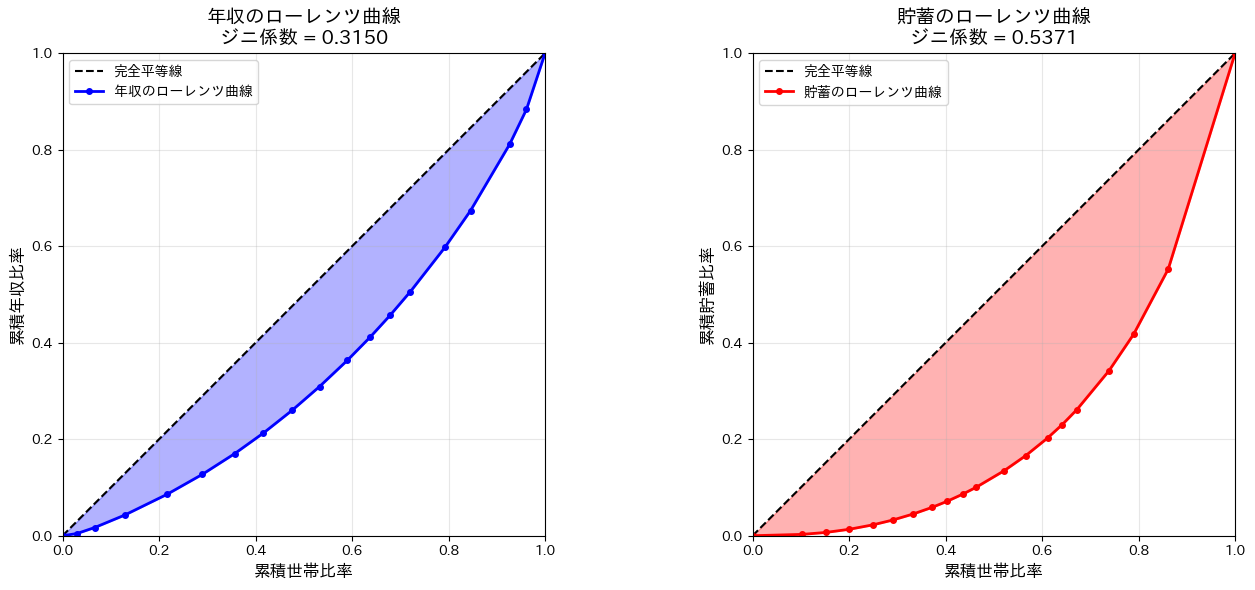

In [14]:
# グラフの作成
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 年収のローレンツ曲線
ax1 = axes[0]
ax1.plot([0, 1], [0, 1], 'k--', label='完全平等線', linewidth=1.5)
ax1.plot(income_cum_pop, income_cum_value, 'b-', label=f'年収のローレンツ曲線', linewidth=2, marker='o', markersize=4)
ax1.fill_between(income_cum_pop, income_cum_value, income_cum_pop, alpha=0.3, color='blue')
ax1.set_xlabel('累積世帯比率', fontsize=12)
ax1.set_ylabel('累積年収比率', fontsize=12)
ax1.set_title(f'年収のローレンツ曲線\nジニ係数 = {income_gini:.4f}', fontsize=14)
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.set_aspect('equal')

# 貯蓄のローレンツ曲線
ax2 = axes[1]
ax2.plot([0, 1], [0, 1], 'k--', label='完全平等線', linewidth=1.5)
ax2.plot(savings_cum_pop, savings_cum_value, 'r-', label=f'貯蓄のローレンツ曲線', linewidth=2, marker='o', markersize=4)
ax2.fill_between(savings_cum_pop, savings_cum_value, savings_cum_pop, alpha=0.3, color='red')
ax2.set_xlabel('累積世帯比率', fontsize=12)
ax2.set_ylabel('累積貯蓄比率', fontsize=12)
ax2.set_title(f'貯蓄のローレンツ曲線\nジニ係数 = {savings_gini:.4f}', fontsize=14)
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.set_aspect('equal')

plt.tight_layout()
plt.savefig('lorenz_curves_separate.png', dpi=150, bbox_inches='tight')
plt.show()

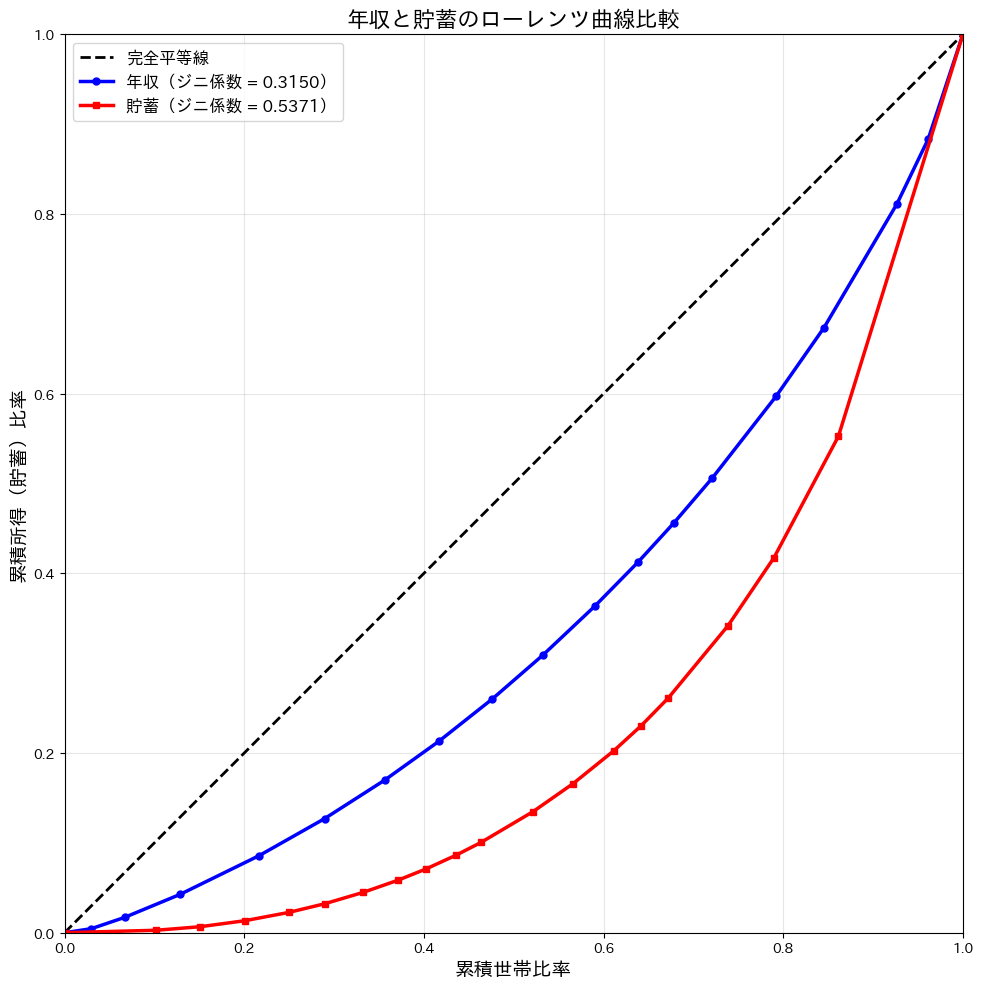

In [15]:
# 両方のローレンツ曲線を重ねて表示
fig, ax = plt.subplots(figsize=(10, 10))

ax.plot([0, 1], [0, 1], 'k--', label='完全平等線', linewidth=2)
ax.plot(income_cum_pop, income_cum_value, 'b-',
        label=f'年収（ジニ係数 = {income_gini:.4f}）', linewidth=2.5, marker='o', markersize=5)
ax.plot(savings_cum_pop, savings_cum_value, 'r-',
        label=f'貯蓄（ジニ係数 = {savings_gini:.4f}）', linewidth=2.5, marker='s', markersize=5)

ax.set_xlabel('累積世帯比率', fontsize=14)
ax.set_ylabel('累積所得（貯蓄）比率', fontsize=14)
ax.set_title('年収と貯蓄のローレンツ曲線比較', fontsize=16)
ax.legend(loc='upper left', fontsize=12)
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect('equal')

plt.tight_layout()
plt.savefig('lorenz_curves_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. 結果のまとめ

In [16]:
# 結果のまとめ表示
print("="*60)
print("          ジニ係数の比較結果")
print("="*60)
print(f"\n  年収（フロー）のジニ係数:    {income_gini:.4f}")
print(f"  貯蓄（ストック）のジニ係数:  {savings_gini:.4f}")
print(f"\n  差（貯蓄 - 年収）:           {savings_gini - income_gini:.4f}")
print("="*60)

if savings_gini > income_gini:
    print("\n  → 貯蓄（ストック）の格差の方が大きい")
else:
    print("\n  → 年収（フロー）の格差の方が大きい")

          ジニ係数の比較結果

  年収（フロー）のジニ係数:    0.3150
  貯蓄（ストック）のジニ係数:  0.5371

  差（貯蓄 - 年収）:           0.2221

  → 貯蓄（ストック）の格差の方が大きい


## 7. 考察

### 分析結果

ジニ係数の計算結果から、**貯蓄（ストック）の格差は年収（フロー）の格差よりも大きい**ことがわかります。

### なぜ貯蓄の格差の方が大きいのか？

この差が生じる主な理由として、以下の要因が考えられます：

#### 1. **蓄積効果（複利効果）**
- 貯蓄は年収の蓄積であり、長期間にわたって積み重なるため、格差が拡大しやすい
- 高所得者は消費後も余剰資金を貯蓄に回せるが、低所得者は生活費で精一杯となり貯蓄が難しい
- この差が毎年積み重なることで、ストックの格差はフローの格差を上回る

#### 2. **資産運用による格差拡大**
- 一定以上の貯蓄があれば投資や資産運用が可能となり、さらに資産を増やせる
- 貯蓄が少ない世帯は運用益を得る機会が限られる
- 「お金がお金を生む」仕組みにより、富裕層と非富裕層の差が拡大

#### 3. **世代間の資産移転（相続）**
- 親世代からの相続により、労働所得とは無関係に資産格差が生じる
- 相続は主に貯蓄（ストック）に影響し、年収（フロー）には直接影響しない

#### 4. **ライフステージの影響**
- 若年層は所得があっても貯蓄が少なく、高齢層は退職後も過去の蓄積がある
- 年収は労働期間に限定されるが、貯蓄は生涯を通じて変動

#### 5. **消費・貯蓄行動の差異**
- 同じ年収でも消費性向（消費に回す割合）は世帯によって異なる
- 計画的な貯蓄習慣の有無が長期的な貯蓄額の差を生む

### まとめ

年収は毎年のフローであるため、景気変動や転職などで変化しても一定の範囲に収まりやすいのに対し、貯蓄は長年の蓄積であり、一度生じた格差が自己増殖的に拡大する傾向があります。これが「フローよりストックの格差が大きい」という結果につながっています。

この現象は「ピケティの r > g」（資本収益率が経済成長率を上回る）とも関連し、資産格差が所得格差を上回る傾向は世界的にも観察されています。